<p align="center">
    <img src="https://beyondeducation.es/wp-content/uploads/2024/02/CUNEF-UNI50.png" width="500">
</p>


<h1 align="center"><b>Initial Assignment - Machine Learning</b></h1>
<h2 align="center">M2026-27 - Master in Data Science and Artificial Intelligence</h2>

| Full name | CUNEF email |
|---|---|
| Melanie Álvarez | melanie.alvarez@cunef.edu |
| María Victoria del Campo | victoria.delcampo@cunef.edu |
| Alicia Plaza | alicia.plaza@cunef.edu |

**GitHub repository:** https://github.com/mvdelcampo/machine-learning-project

In [ ]:
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# **Data loading**

In [ ]:
bacteria_dataset = pd.read_csv("../data/Bacteria_dataset_Multiresictance.csv")
print("Dataset loaded successfully!")

Dataset loaded successfully!


# **Exploratory Data Analysis**

## 1. Data description and inspection

In [3]:
bacteria_dataset.shape

(10710, 27)

In [156]:
bacteria_dataset.head()

,ID,Name,Email,Address,age/gender,Souches,Diabetes,Hypertension,Hospital_before,Infection_Freq,...,AN,Acide nalidixique,ofx,CIP,C,Co-trimoxazole,Furanes,colistine,Collection_Date,Notes
0,S290,Elizabeth Lawrence,elizabeth.lawrence@example.com,"6350 Robinson Loaf Apt. 447, Paulfurt, RI 30252",37/F,S290 Escherichia coli,No,No,No,0.0,...,S,S,S,S,R,S,S,S,5 Fev 2025,Patient had fever??
1,S291,Tina Sanders,tina.sanders@example.com,"78594 Galloway Port Suite 762, South Tanyatown...",29/F,S291 Morganella morganii,True,No,No,3.0,...,S,S,S,S,S,S,S,S,08/05/2021,تم العلاج
2,S292,Erin Cooke,erin.cooke@example.com,"76661 Isaiah Manors, North Benjamin, HI 85195",77/F,S292 Proteus mirabilis,True,No,No,3.0,...,S,S,S,R,R,S,S,S,01/05/2022,NADA
3,S293,Mrs. Sharon Watson,mrs..sharon.watson@example.com,"1670 Thompson Way Apt. 520, Andrewbury, IL 11534",NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-01-05,PACIENTO ENFERMO
4,S294,Erika Stewart,erika.stewart@example.com,"76838 Patrick Green Suite 538, Torresmouth, ME...",13/F,S294 Escherichia coli,No,Yes,No,1.0,...,R,S,S,S,S,S,S,S,error,NADA


In [26]:
inspection = pd.DataFrame({
    "dtype": bacteria_dataset.dtypes.astype(str),
    "non_null": bacteria_dataset.notna().sum(),
    "missing_pct": (bacteria_dataset.isna().mean() * 100).round(2),
    "n_unique": bacteria_dataset.nunique(dropna=True),
}).sort_values("missing_pct", ascending=False)

inspection

,dtype,non_null,missing_pct,n_unique
Collection_Date,str,10041,6.25,13
AMX/AMP,str,10052,6.14,8
GEN,str,10067,6.00,8
Souches,str,10070,5.98,9298
Co-trimoxazole,str,10070,5.98,8
Infection_Freq,str,10071,5.97,8
Hospital_before,str,10073,5.95,4
Furanes,str,10073,5.95,8
colistine,str,10074,5.94,8
Diabetes,str,10075,5.93,4


The `Name`, `Email`, and `Address` columns contain personally identifiable information (PII) that could reveal a patient's identity. To protect patient privacy and follow data protection principles, this information should not be included in the analysis. Since these variables are not relevant to predicting antibiotic resistance, they are removed from the dataset. Additionally, the `Collection_Date` column is also dropped because it is not considered relevant to the project's prediction objective.

In [27]:
bacteria_dataset.drop(columns=['Name', 'Email', 'Address', 'Collection_Date'], inplace=True)

/var/folders/50/v1zvnbhs24g12w629ddg43dm0000gn/T/ipykernel_46377/3470330596.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  bacteria_dataset.drop(columns=['Name', 'Email', 'Address', 'Collection_Date'], inplace=True)


## 2. Duplicates

No duplicate records, repeated IDs, or missing ID values were found in the dataset. This confirms that all records have unique and valid identifiers, so no further investigation or cleaning is required regarding duplicates.

In [28]:
print("Duplicated full records:", bacteria_dataset.duplicated().sum())
print("Repeated ID values:", bacteria_dataset['ID'].duplicated().sum())
print("Rows with a null ID:", bacteria_dataset['ID'].isna().sum())

Duplicated full records: 0
Repeated ID values: 0
Rows with a null ID: 0


## 3. Data cleaning

### 3.1 Age and gender

The raw `age/gender` values may contain a number and F/M separated by `/`. We inspect exceptions, split the fields and convert age to numeric to enable distribution and outliers analysis.

In [29]:
bacteria_dataset["age/gender"].unique()

<StringArray>
['37/F', '29/F', '77/F',    nan, '13/F', '57/M', '68/F', '18/F', '36/F',
 '49/M',
 ...
  '1/M', '67/M', '32/M', '23/M', '70/M', '37/M', '77/M', '10/M', '34/M',
 '66/M']
Length: 185, dtype: str

In [30]:
columna = bacteria_dataset["age/gender"].astype("string")

columna[
    ~columna.str.fullmatch(r"\d+\s*/\s*[FM]", case=False, na=False)
].unique()

<StringArray>
[<NA>, 'missing', '?']
Length: 3, dtype: string

We will now split the age/gender column into two separate columns, `Age` and `Gender`. First, it converts the values to strings and removes unnecessary spaces. Then, invalid values such as "missing", "nan", and "?" are replaced with missing values (`pd.NA`). Finally, it splits the column using / as the separator.

This makes the data easier to analyze and prepares both variables for further preprocessing and Machine Learning.

In [31]:
age_gender = bacteria_dataset["age/gender"].astype("string").str.strip()
age_gender = age_gender.mask(
    age_gender.str.lower().isin(["missing", "nan", "?"])
)

bacteria_dataset[["Age", "Gender"]] = age_gender.str.split("/", expand=True)

In [32]:
bacteria_dataset['Age'] = pd.to_numeric(bacteria_dataset['Age'], errors='coerce')

In [33]:
bacteria_dataset.head()

,ID,age/gender,Souches,Diabetes,Hypertension,Hospital_before,Infection_Freq,AMX/AMP,AMC,CZ,...,Acide nalidixique,ofx,CIP,C,Co-trimoxazole,Furanes,colistine,Notes,Age,Gender
0,S290,37/F,S290 Escherichia coli,No,No,No,0.0,R,R,R,...,S,S,S,R,S,S,S,Patient had fever??,37,F
1,S291,29/F,S291 Morganella morganii,True,No,No,3.0,S,R,S,...,S,S,S,S,S,S,S,تم العلاج,29,F
2,S292,77/F,S292 Proteus mirabilis,True,No,No,3.0,S,R,S,...,S,S,R,R,S,S,S,NADA,77,F
3,S293,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PACIENTO ENFERMO,<NA>,<NA>
4,S294,13/F,S294 Escherichia coli,No,Yes,No,1.0,S,S,R,...,S,S,S,S,S,S,S,NADA,13,F


In [34]:
bacteria_dataset.drop(columns=['age/gender'], inplace=True)

/var/folders/50/v1zvnbhs24g12w629ddg43dm0000gn/T/ipykernel_46377/2268476397.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  bacteria_dataset.drop(columns=['age/gender'], inplace=True)


### 3.2. Clinical binary variables

The `Diabetes`, `Hypertension`, and `Hospital_before` columns are converted into binary variables (0 = No, 1 = Yes) to make them easier to analyze and use in Machine Learning models. Missing values are preserved for further processing.

In [35]:
mapping = {"true": 1, "yes": 1, "false": 0, "no": 0}

for col in ["Diabetes", "Hypertension", "Hospital_before"]:
    values = bacteria_dataset[col].astype("string").str.strip().str.lower()
    values = values.replace({"?": pd.NA, "missing": pd.NA, "": pd.NA})

    unexpected = set(values.dropna().unique()) - set(mapping)
    if unexpected:
        raise ValueError(f"Unexpected values in {col}: {unexpected}")

    bacteria_dataset[col] = values.map(mapping).astype("Int64")

### 3.3. Bacterial species (`Souches`)

The `Souches` column contains a patient identification prefix (e.g., `S687`) followed by the bacterial species name. Some species names also contain spelling errors or inconsistent abbreviations. First, we identify these inconsistencies, then remove the identification prefixes and correct the names to ensure that each bacterial species is represented consistently. Invalid or missing values are also standardized as `pd.NA`.

In [36]:
# Remove the first word, preserving single-word values
souches = bacteria_dataset["Souches"].astype("string").str.strip()

souches_without_id = (
    souches
    .str.split(n=1)
    .str[1]
    .fillna(souches)
    .str.strip()
)

# Check unique values
print("=== UNIQUE BACTERIAL SPECIES ===")
print(souches_without_id.unique())

print("\n=== BACTERIAL SPECIES FREQUENCY ===")
print(souches_without_id.value_counts(dropna=False))

print("\n=== TOTAL UNIQUE SPECIES ===")
print(souches_without_id.nunique())

=== UNIQUE BACTERIAL SPECIES ===
['Escherichia coli' 'Morganella morganii' 'Proteus mirabilis' <NA>
 'Citrobacter spp.' 'Enterobacteria spp.' 'Proeus mirabilis'
 'Pseudomonas aeruginosa' 'Klebsiella pneumoniae' 'E. coli'
 'Klbsiella pneumoniae' 'E.cli' 'E.coi' 'Serratia marcescens'
 'Klebsie.lla pneumoniae' 'Acinetobacter baumannii' 'Prot.eus mirabilis'
 'missing' 'Protus mirabilis' 'Enter.bacteria spp.' '?'
 'Enteobacteria spp.']

=== BACTERIAL SPECIES FREQUENCY ===
Souches
Escherichia coli           4864
Enterobacteria spp.         802
<NA>                        640
Proteus mirabilis           598
Klebsiella pneumoniae       565
Citrobacter spp.            481
E.coi                       432
E.cli                       396
E. coli                     391
Morganella morganii         305
Serratia marcescens         256
Pseudomonas aeruginosa      200
Acinetobacter baumannii     181
Enter.bacteria spp.         100
Enteobacteria spp.           95
Klbsiella pneumoniae         74
Klebsie.

In [37]:
# Dictionary to correct bacterial species names
corrections = {
    'E. coli': 'Escherichia coli',
    'E.cli': 'Escherichia coli',
    'E.coi': 'Escherichia coli',

    'Klbsiella pneumoniae': 'Klebsiella pneumoniae',
    'Klebsie.lla pneumoniae': 'Klebsiella pneumoniae',

    'Proeus mirabilis': 'Proteus mirabilis',
    'Prot.eus mirabilis': 'Proteus mirabilis',
    'Protus mirabilis': 'Proteus mirabilis',

    'Enter.bacteria spp.': 'Enterobacteria spp.',
    'Enteobacteria spp.': 'Enterobacteria spp.'
}

# Clean and standardize bacterial species
bacteria_dataset["Souches"] = (
    bacteria_dataset["Souches"]
    .astype("string")
    .str.strip()
    .str.replace(r"^S\d+\s+", "", regex=True)  # Remove sample ID
    .str.strip()
    .replace(corrections)  # Correct typos
    .replace(
        r"(?i)^(missing|na|nan|none|null|\?)$",
        pd.NA,
        regex=True
    )  # Replace missing indicators with pd.NA
)

In [38]:
print("=== UNIQUE BACTERIAL SPECIES (AFTER CLEANING) ===")
print(bacteria_dataset["Souches"].unique())

print("\n=== BACTERIAL SPECIES FREQUENCY (AFTER CLEANING) ===")
print(bacteria_dataset["Souches"].value_counts(dropna=False))

print("\n=== TOTAL UNIQUE SPECIES (AFTER CLEANING) ===")
print(bacteria_dataset["Souches"].nunique())

=== UNIQUE BACTERIAL SPECIES (AFTER CLEANING) ===
<StringArray>
[       'Escherichia coli',     'Morganella morganii',
       'Proteus mirabilis',                      <NA>,
        'Citrobacter spp.',     'Enterobacteria spp.',
  'Pseudomonas aeruginosa',   'Klebsiella pneumoniae',
     'Serratia marcescens', 'Acinetobacter baumannii']
Length: 10, dtype: string

=== BACTERIAL SPECIES FREQUENCY (AFTER CLEANING) ===
Souches
Escherichia coli           6083
Enterobacteria spp.         997
<NA>                        763
Proteus mirabilis           742
Klebsiella pneumoniae       702
Citrobacter spp.            481
Morganella morganii         305
Serratia marcescens         256
Pseudomonas aeruginosa      200
Acinetobacter baumannii     181
Name: count, dtype: Int64

=== TOTAL UNIQUE SPECIES (AFTER CLEANING) ===
9


### 3.4. Antibiotic susceptibility results

The dataset contains susceptibility results for 15 antibiotics. In this step, we clean and standardize the values into: `R` (Resistant), `S` (Susceptible), and `I` (Intermediate). We also identify invalid entries and convert them into missing values. Keeping these categories separate preserves the original susceptibility information for further analysis and preprocessing.

In [39]:
bacteria_dataset["AMC"].value_counts(dropna=False)

AMC
R               5719
S               3876
NaN              632
i                 97
r                 96
s                 94
Intermediate      75
missing           66
?                 55
Name: count, dtype: int64

In [40]:
antibiotics = [
    "AMX/AMP", "AMC", "CZ", "FOX", "CTX/CRO", "IPM", "GEN", "AN",
    "Acide nalidixique", "ofx", "CIP", "C", "Co-trimoxazole",
    "Furanes", "colistine"
]

# Normalize text: remove spaces and standardize capitalization
values = bacteria_dataset[antibiotics].astype("string")
values = values.apply(lambda column: column.str.strip().str.upper())

# Standardize missing values and "Intermediate"
values = values.replace({
    "": pd.NA,
    "MISSING": pd.NA,
    "?": pd.NA,
    "NAN": pd.NA,
    "INTERMEDIATE": "I"
})

# Verify that no categories other than R, S, I, or NA remain.
unexpected_antibiotics = {
    column: sorted(values[column].dropna().unique().tolist())
    for column in antibiotics
    if not values[column].dropna().isin(["R", "S", "I"]).all()
}

if unexpected_antibiotics:
    raise ValueError(f"Unexpected values in antibiotics columns: {unexpected_antibiotics}")

bacteria_dataset[antibiotics] = values

In [41]:
# Confirm vocabulary of all 15 antibiotic columns after standardization.
antibiotic_check = pd.DataFrame({
    "R": (bacteria_dataset[antibiotics] == "R").sum(),
    "S": (bacteria_dataset[antibiotics] == "S").sum(),
    "I": (bacteria_dataset[antibiotics] == "I").sum(),
    "missing": bacteria_dataset[antibiotics].isna().sum()
})

# Total count for each antibiotic
antibiotic_check["Total"] = antibiotic_check.sum(axis=1)

antibiotic_check

,R,S,I,missing,Total
AMX/AMP,5712,4061,184,753,10710
AMC,5815,3970,172,753,10710
CZ,5690,4097,170,753,10710
FOX,5735,4049,173,753,10710
CTX/CRO,5748,4026,183,753,10710
IPM,5717,4054,186,753,10710
GEN,1936,7854,167,753,10710
AN,1905,7875,177,753,10710
Acide nalidixique,1388,8379,190,753,10710
ofx,1381,8406,170,753,10710


Later before the modelling stage, we might have to encode these labels. The type of encoding may depend on the model, but an ordinal encoding (S = 0, I = 1, R = 2) is a natural choice, since the categories follow a clear order.

### 3.5. Infection frequency

The `Infection_Freq` column represents the frequency of infections per patient. 

In [42]:
display(bacteria_dataset["Infection_Freq"].value_counts(dropna=False))


Infection_Freq
2.0        2966
1.0        2889
3.0        1963
0.0        1896
NaN         639
missing     131
unknown      81
error        81
?            64
Name: count, dtype: int64

The values represent this encoded categories according to the data source:

    0 = Never, 1 = Rarely, 2 = Regularly, 3 = Often

For now, we decided to keep this variable in the dataset. A priori, it does not seem strongly related to the prediction objective, but we keep it as a precaution.
We apply a similar cleaning process to the fields: invalid entries are standardized as `pd.NA` and the column is cast to integer.

In [43]:
freq = bacteria_dataset["Infection_Freq"].astype("string").str.strip().str.lower()
freq = freq.replace({"?": pd.NA, "missing": pd.NA, "unknown": pd.NA,
                     "error": pd.NA, "nan": pd.NA, "": pd.NA})

freq = pd.to_numeric(freq, errors="coerce")

# Check: only integers between 0 and 3
invalid = freq.dropna()[(freq.dropna() % 1 != 0) | ~freq.dropna().between(0, 3)]
if not invalid.empty:
    raise ValueError(f"Unexpected values in Infection_Freq: {invalid.unique()}")

bacteria_dataset["Infection_Freq"] = freq.astype("Int64")


### 3.6. Notes

After reviewing the `Notes` column, we found that it does not provide relevant information about the patients or useful features for predicting ciprofloxacin resistance. Therefore, this column is removed from the dataset to reduce unnecessary information.

In [44]:
print(f"\n=== Notes ===")

print("Missing values:", bacteria_dataset["Notes"].isna().sum())
print("Unique values:", bacteria_dataset["Notes"].nunique())
display(bacteria_dataset["Notes"].value_counts(dropna=False))


=== Notes ===
Missing values: 112
Unique values: 9


Notes
see file               1508
MALADIE GRAVE          1507
Patient had fever??    1505
--                     1504
تم العلاج              1500
PACIENTO ENFERMO       1490
NADA                   1452
NaN                     112
?                        72
missing                  60
Name: count, dtype: int64

In [45]:
bacteria_dataset.drop(columns=['Notes'], inplace=True)

/var/folders/50/v1zvnbhs24g12w629ddg43dm0000gn/T/ipykernel_46377/2953118997.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  bacteria_dataset.drop(columns=['Notes'], inplace=True)


## 4. Missing data analysis

In [46]:
bacteria_dataset.isna().sum()[lambda x: x > 0]

Souches              763
Diabetes             763
Hypertension         763
Hospital_before      763
Infection_Freq       996
AMX/AMP              753
AMC                  753
CZ                   753
FOX                  753
CTX/CRO              753
IPM                  753
GEN                  753
AN                   753
Acide nalidixique    753
ofx                  753
CIP                  753
C                    753
Co-trimoxazole       753
Furanes              753
colistine            753
Age                  763
Gender               763
dtype: int64

Rows without a value for `CIP` are removed, since the target is required for both training and evaluating the model and cannot be imputed without introducing bias.

In [47]:
print("Rows without CIP:", bacteria_dataset["CIP"].isna().sum())

n_before = len(bacteria_dataset)
missing_cip = bacteria_dataset["CIP"].isna()
bacteria_dataset = bacteria_dataset[~missing_cip].reset_index(drop=True)
print(f"Rows before: {n_before} | Rows after: {len(bacteria_dataset)}")

Rows without CIP: 753
Rows before: 10710 | Rows after: 9957


In [48]:
bacteria_dataset.isna().sum()[lambda x: x > 0]

Souches             10
Diabetes            10
Hypertension        10
Hospital_before     10
Infection_Freq     243
Age                 10
Gender              10
dtype: int64

In [49]:
cols = ["Souches", "Diabetes", "Hypertension", "Hospital_before", "Age", "Gender"]
all_missing = bacteria_dataset[cols].isna().all(axis=1)
print("Rows with ALL these columns missing:", all_missing.sum())


Rows with ALL these columns missing: 10


This rows without any patient information represent a negligible share of the dataset, so we are also removing them.

In [50]:
bacteria_dataset = bacteria_dataset[~all_missing].reset_index(drop=True)

The only variable with NAs left is `Infection_Freq`. Since the rest of these records is complete, we keep them and impute the missing values instead of removing the rows.

Before choosing an imputation strategy, we check whether the missingness is related to the target. The code below compares the proportion of CIP = R in rows where `Infection_Freq` is missing with the proportion in rows where it is present.

In [51]:
cip_r = bacteria_dataset["CIP"].eq("R")
m = bacteria_dataset["Infection_Freq"].isna()
print(f"n missing: {m.sum()} | R-rate if missing: {cip_r[m].mean():.2f} | if present: {cip_r[~m].mean():.2f}")


n missing: 233 | R-rate if missing: 0.12 | if present: 0.15


Because both rates are similar, the missingness does not appear to depend on the target, and a simple imputation will not introduce bias. The imputation has to be performed after splitting the data into training and test sets, and the median is calculated on the training set only. This median is then used to fill the missing values in both sets. If it were computed on the full dataset, information from the test set would influence the training data (**data leakage**).


In [183]:
# CODE TO ADD AFTER THE train_test_split IS DONE:

# median_freq = X_train["Infection_Freq"].median()

# X_train["Infection_Freq"] = X_train["Infection_Freq"].fillna(median_freq)
# X_test["Infection_Freq"] = X_test["Infection_Freq"].fillna(median_freq)

## 5. Outliers
There were no outliers found in the dataset. Most of the variable of the dataset are categorical, and the only numerical variable in the dataset is `Age`. The boxplot for `Age` shows that there are no outliers in the data, and in section 7 it will be shown grouped by the target variable.

## 6. Target formulation: ciprofloxacin (CIP)

For each patient, the lab grows the bacteria and tests whether ciprofloxacin is able to stop it. The result is reported in one of three categories:

- **S (susceptible):** the antibiotic works against the bacteria.
- **R (resistant):** the antibiotic does not work; the infection would keep growing despite the treatment.
- **I (intermediate):** a borderline result. The antibiotic may work under certain conditions (for example, a higher dose), but its effect is uncertain.

Our goal is to predict **resistance (R)**. A model that flags likely resistant cases in advance helps avoid ineffective treatments. For this reason, R is the positive class (1). Failing to detect a resistant case is the most costly error.

Before building the binary target, we need to decide what to do with the intermediate (I) results, since they do not clearly belong to either class.

In [54]:
# Distribution of the CIP result (absolute and relative)
cip_dist = pd.DataFrame({
    "count": bacteria_dataset["CIP"].value_counts(),
    "percentage": bacteria_dataset["CIP"].value_counts(normalize=True).mul(100).round(2)
})
display(cip_dist)


,count,percentage
CIP,,
S,8330,83.74
R,1444,14.52
I,173,1.74


Intermediate results are a very small group compared with the other two categories. Before deciding what to do with them, we check whether they behave more like resistant or like susceptible isolates. To do so, we compare the three groups based on their results for the other 14 antibiotics.

In [55]:
# Profile of each CIP group based on the results of the other antibiotics
other_antibiotics = [a for a in antibiotics if a != "CIP"]

profile = pd.DataFrame({
    "n_isolates": bacteria_dataset["CIP"].value_counts(),
    "avg_R_other_antibiotics": (bacteria_dataset[other_antibiotics] == "R").sum(axis=1)
                                .groupby(bacteria_dataset["CIP"]).mean().round(2),
    "avg_S_other_antibiotics": (bacteria_dataset[other_antibiotics] == "S").sum(axis=1)
                                    .groupby(bacteria_dataset["CIP"]).mean().round(2),
    "avg_I_other_antibiotics": (bacteria_dataset[other_antibiotics] == "I").sum(axis=1)
                                .groupby(bacteria_dataset["CIP"]).mean().round(2),
}).loc[["S", "R", "I"]]

display(profile)

,n_isolates,avg_R_other_antibiotics,avg_S_other_antibiotics,avg_I_other_antibiotics
CIP,,,,
S,8330,4.57,9.36,0.08
R,1444,5.42,8.16,0.43
I,173,3.47,3.72,6.8


* **Intermediate results are rare.** They represent only about 1.7% of the labelled isolates, so removing them barely affects the size of the dataset.

* **They do not look like resistant isolates.** On average, they are resistant to fewer of the other antibiotics than even the susceptible ones. Merging them with the resistant class would add questionable labels to the class we care most about, which is also the smallest one.

* **They seem to follow their own pattern.** Isolates with CIP = I also show an intermediate result in about half of the other antibiotics (6.8 out of 14), while this almost never happens in the other groups (<0.5). This points to a recording pattern in the data rather than to bacteria that are truly "in between".

* **There is no extra information to place them.** The dataset does not include the exact lab measurements behind each result, so any assignment to R or S would be a guess.

**Decision:** we remove isolates with CIP = I and define a binary target: **R = 1 (resistant)** and **S = 0 (susceptible)**. Later, in the modelling stage we could also train a version where I is treated as R (the cautious option from a medical point of view) and compare the results.

Merging intermediate results with the susceptible class would also be reasonable, since their profile is closer to susceptible isolates. However, labelling uncertain cases as "the antibiotic works" goes against the goal of the model, which is to warn when it may not. Removing them avoids forcing either choice.

*Limitation:* in a real setting the model would also receive intermediate cases, which it has not been trained on.

In [56]:
# Remove intermediate results and encode the target
n_before = len(bacteria_dataset)
bacteria_dataset = bacteria_dataset[bacteria_dataset["CIP"] != "I"].copy()
print(f"Rows removed (CIP = I): {n_before - len(bacteria_dataset)}")

bacteria_dataset["CIP"] = bacteria_dataset["CIP"].map({"R": 1, "S": 0}).astype(int)

Rows removed (CIP = I): 173


## 7. Distributions and descriptive analysis

In [63]:
cip_values = ["S", "R"]
cip_label = bacteria_dataset["CIP"].map({0: "S", 1: "R"})
cip_r = bacteria_dataset["CIP"].eq(1)

other_antibiotics = [ab for ab in antibiotics if ab != "CIP"]

### 7.1 Target distribution

The first plot shows a bar chart with the number and percentage of isolates in each CIP class. In this way, the class balance of the target can be observed to decide how to split the data for training and in which metrics we can trust.

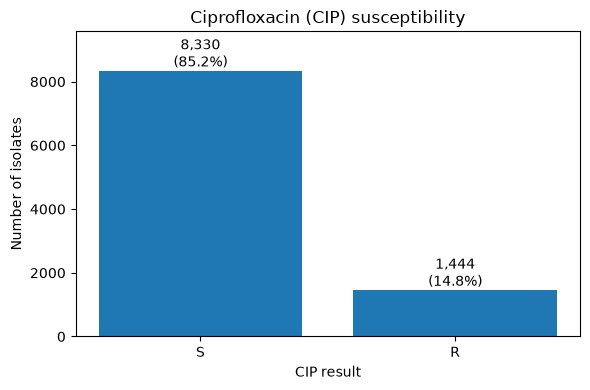

In [64]:
cip_counts = cip_label.value_counts().reindex(cip_values)
cip_pct = cip_counts / cip_counts.sum() * 100

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(cip_values, cip_counts.values)
for i, (n, p) in enumerate(zip(cip_counts, cip_pct)):
    ax.text(i, n, f"{n:,}\n({p:.1f}%)", ha="center", va="bottom")
ax.set_ylim(0, cip_counts.max() * 1.15)
ax.set_title("Ciprofloxacin (CIP) susceptibility")
ax.set_xlabel("CIP result")
ax.set_ylabel("Number of isolates")
plt.tight_layout()
plt.show()

The graph shows that the target is imbalanced. There are 8,330 susceptible isolates (85.2%) and 1.444 resistant ones (14.8%). A model that always predicted S would reach 85.2% accuracy without detecting a single resistant isolate, which means:

* Accuracy cannot be the main metric. We will report recall, precision, F1 and PR-AUC for the positive class (R), giving priority to recall because missing a resistant isolate is the costly error (section 6).

* The `train_test_split` must be stratified by CIP, so that train and test keep the same ~15% of R.

### 7.2 CIP resistance by the result of each other antibiotic

For each of the other 14 antibiotics, the green dot is the percentage (%) of CIP = R among isolates susceptible (S) to that antibiotic and the blue dot among isolates resistant (R) to it. 

Antibiotics are sorted by the gap in percentage points between these two. This is important because it shows how informative each candidate feature is. The longer the line, the more the result of that antibiotic changes the probability of CIP resistance. 

Isolates with an intermediate result (I) in the other antibiotics (fewer than 100 per antibiotic) are not drawn here and are discussed below.

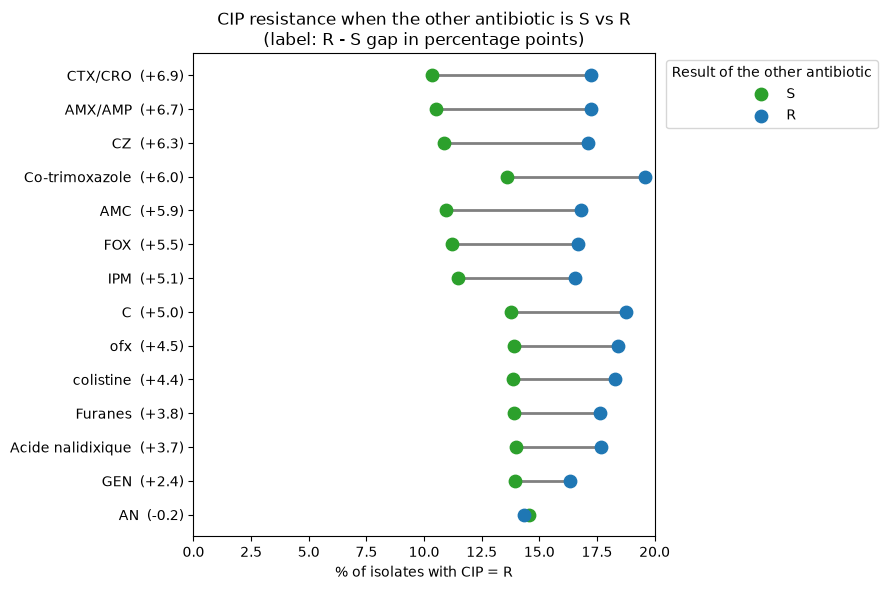

In [65]:
rates = pd.DataFrame({
    ab: bacteria_dataset.groupby(ab)["CIP"].mean() * 100
    for ab in other_antibiotics
}).T.reindex(columns=cip_values)
rates["gap"] = rates["R"] - rates["S"]
rates = rates.sort_values("gap")  # largest gap ends up on top

fig, ax = plt.subplots(figsize=(9, 6))
y = np.arange(len(rates))
ax.hlines(y, rates["S"], rates["R"], color="grey", lw=2, zorder=1)
ax.scatter(rates["S"], y, color="tab:green", s=80, label="S", zorder=2)
ax.scatter(rates["R"], y, color="tab:blue", s=80, label="R", zorder=2)

ax.set_yticks(y, [f"{ab}  ({gap:+.1f})" for ab, gap in rates["gap"].items()])
ax.set_xlabel("% of isolates with CIP = R")
ax.set_title("CIP resistance when the other antibiotic is S vs R\n(label: R - S gap in percentage points)")
ax.legend(title="Result of the other antibiotic", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.xlim(0, 20)
plt.tight_layout()
plt.show()

The graph shows that being resistant to any other antibiotic raises the chance of being resistant to CIP, as almost all blue dots have a greater percentage value than the green dots. However, the effect is moderate and largest for the **beta-lactams**, a family of antibiotics that share a chemical structure: `CTX/CRO`, `AMX/AMP`, `CZ`, `AMC`, `FOX`, `IMP`. The antibiotic `AN` has no marginal effect.

As a result, all antibiotics should be kept as candidates for modeling and combine them, with `AN` being probably the first one to drop.

In [69]:
# Isolates with an intermediate (I) result in any of the other 14 antibiotics
has_I = (bacteria_dataset[other_antibiotics] == "I").any(axis=1)
pd.DataFrame({
    "n_isolates": has_I.value_counts(),
    "pct_CIP_R": bacteria_dataset["CIP"].groupby(has_I).mean().mul(100).round(1),
}).rename(index={False: "no I in other antibiotics", True: "I in some other antibiotic"})

,n_isolates,pct_CIP_R
no I in other antibiotics,9595,14.1
I in some other antibiotic,179,49.7


The analysis of isolates with an intermediate result (I) in the rest of antibiotics shows that only 179 isolates have an I in other antibiotics, but 49.7% of them are CIP = R against 14.1% for the rest.

Therefore, I does not lie between S and R in the rest of antibiotics, as we discussed previously with CIP. Therefore, we will one-hot encode the antibiotics with I as its own category (not ordinal), or use tree-based models, and check that the models do not over-rely on I.

### 7.3 CIP resistance by bacterial species

The third graph shows a horizontal bar chart showing the percentage of isolates with CIP = R for each species, with the number of isolates in the label. The dashed line is the overall rate, which is 14.8%. 

This plot is useful as it shows whether `Souches` separates resistant from susceptible isolates. The further a bar is from the line, in either direction, the more informative the species.

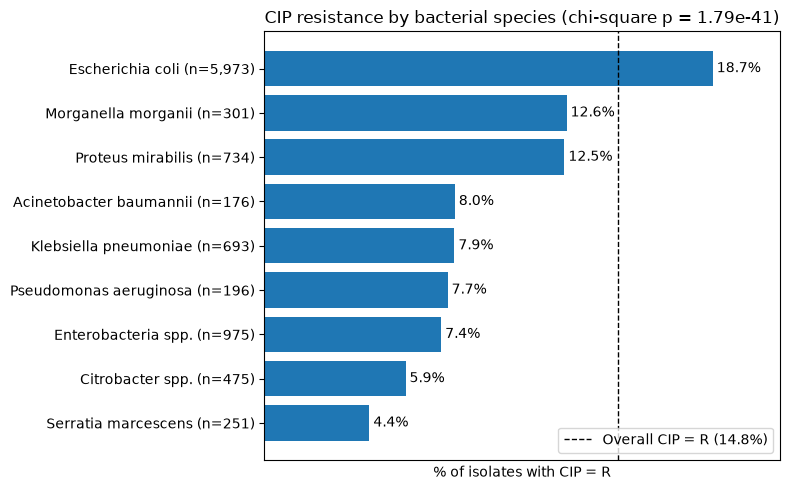

In [66]:
sub = bacteria_dataset[["Souches"]].assign(cip_r=cip_r).dropna()
rate = sub.groupby("Souches")["cip_r"].mean().mul(100).sort_values()
n_group = sub.groupby("Souches").size().reindex(rate.index)
p_value = stats.chi2_contingency(pd.crosstab(sub["Souches"], sub["cip_r"]))[1]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([f"{s} (n={n_group[s]:,})" for s in rate.index], rate.values, color="tab:blue")
ax.axvline(cip_r.mean() * 100, color="black", ls="--", lw=1,
           label=f"Overall CIP = R ({cip_r.mean() * 100:.1f}%)")
for i, r in enumerate(rate):
    ax.text(r, i, f" {r:.1f}%", va="center")
ax.set_xlim(0, rate.max() * 1.15)
ax.set_xlabel("% of isolates with CIP = R")
ax.set_title(f"CIP resistance by bacterial species (chi-square p = {p_value:.3g})")
ax.legend(loc="lower right")
plt.xticks([])
plt.tight_layout()
plt.show()

The bar chart shows that the species matters (chi-square p ≈ 1.8e-41). *E. coli* is the only species above average (18.7%) and *Serratia* is the lowest (4.4%). However, *E. coli* is a species that is present in a big chunk of isolates (5,973) and three species have fewer than 300 isolates, so their rates are noisy.

This means that for feature selection, we should keep `Souches` with one-hot encoding and create a binary *E. coli* versus the rest of species of the variable. Since *E. coli* dominates, we could report metrics for *E. coli* and for the rest separately. The species may also change the effect of the other antibiotics, which tree-based models capture automatically and logistic regression would need interaction terms for.

### 7.4 Age by CIP result

A boxplot of `Age` is created for each CIP class, with the number of isolates and the median in the label. `Age` is the only continuous variable, so we can check differences between classes, its shape and its outliers.

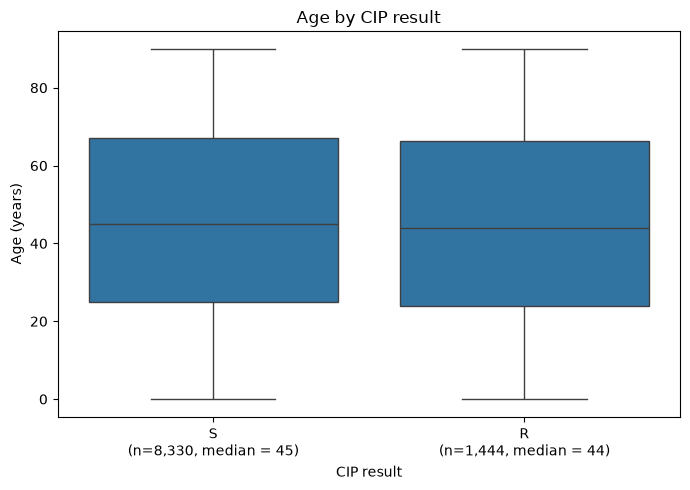

In [67]:
age_df = pd.DataFrame({"CIP": cip_label, "Age": bacteria_dataset["Age"].astype(float)})
age_labels = [
    f"{c}\n(n={age_df['CIP'].eq(c).sum():,}, median = {age_df.loc[age_df['CIP'] == c, 'Age'].median():.0f})"
    for c in cip_values
]

fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=age_df, x="CIP", y="Age", order=cip_values, ax=ax)
ax.set_xticks(range(len(cip_values)), age_labels)
ax.set_title("Age by CIP result")
ax.set_xlabel("CIP result")
ax.set_ylabel("Age (years)")
plt.tight_layout()
plt.show()

The boxplot shows that the classes S and R are almost identical (medians 45 and 44, quartiles 25-67 and 24-66), so `Age` carries little information about CIP. As mentioned in section 5, there are no outliers in the variable. An important remark is that there are 98 isolates with `Age` = 0 , but they are valid because they are most likely infants.

For feature selection, `Age` is kept as a candidate and dropped if it shows no contribution.

### 7.5 CIP resistance by clinical variable

The following dot plot shows the percentage (%) of isolates with CIP = R in each category of the clinical variables, with the number of isolates in the label. The dashed line is the overall rate and the chi-square p-value of each feature is on the right. The plot reveals whether any patient variable separates resistant from susceptible isolates significantly.

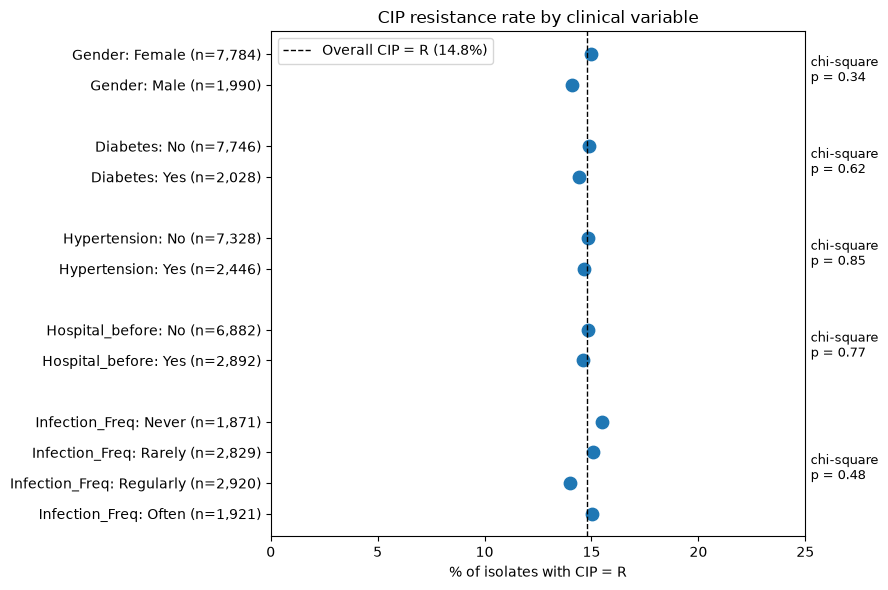

In [68]:
clinical_vars = {
    "Gender": {"F": "Female", "M": "Male"},
    "Diabetes": {0: "No", 1: "Yes"},
    "Hypertension": {0: "No", 1: "Yes"},
    "Hospital_before": {0: "No", 1: "Yes"},
    "Infection_Freq": {0: "Never", 1: "Rarely", 2: "Regularly", 3: "Often"},
}

fig, ax = plt.subplots(figsize=(9, 6))
y, labels_y, pos = [], [], 0
for var, labels in clinical_vars.items():
    sub = bacteria_dataset[[var]].assign(cip_r=cip_r)
    rate = sub.groupby(var)["cip_r"].mean() * 100
    n_group = sub.groupby(var).size()
    p_value = stats.chi2_contingency(pd.crosstab(sub[var], sub["cip_r"]))[1]

    group_pos = list(range(pos, pos + len(rate)))
    ax.scatter(rate.values, group_pos, color="tab:blue", s=80, zorder=2)
    for yi, (k, r) in zip(group_pos, rate.items()):
        labels_y.append(f"{var}: {labels[k]} (n={n_group[k]:,})")
    ax.text(1.01, np.mean(group_pos), f"chi-square\np = {p_value:.2f}", va="center",
            transform=ax.get_yaxis_transform(), fontsize=9)
    y += group_pos
    pos += len(rate) + 1  # blank row between variables

ax.axvline(cip_r.mean() * 100, color="black", ls="--", lw=1,
           label=f"Overall CIP = R ({cip_r.mean() * 100:.1f}%)")
ax.set_yticks(y, labels_y)
ax.invert_yaxis()
ax.set_xlim(0, 25)
ax.set_xlabel("% of isolates with CIP = R")
ax.set_title("CIP resistance rate by clinical variable")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

The conclusion is that none shows a significant difference between CIP classes. All dots are very close to the overall rate, 14.8%, and all p-values are ≥ 0.34. Together with `Age`, no patient characteristic indicates an effect on CIP, unlike the antibiotic profile and the species.

This implies that in feature selection we should test dropping the whole clinical block and `Age`. `Infection_Freq` (233 missing values) only needs imputation (using training median, after the split) if it is kept.

### 7.6 Correlation between antibiotic resistances

For our final graph, we wanted to delve deeper into the relationships among antibiotics. It is shown that their predictive power could be helpful (section 7.2) given the gap they form between different CIP classes. The heatmap of the correlation between the resistance indicators (R = 1, otherwise 0) of all antibiotics, with CIP first, explores whether the predictors are redundant with each other.

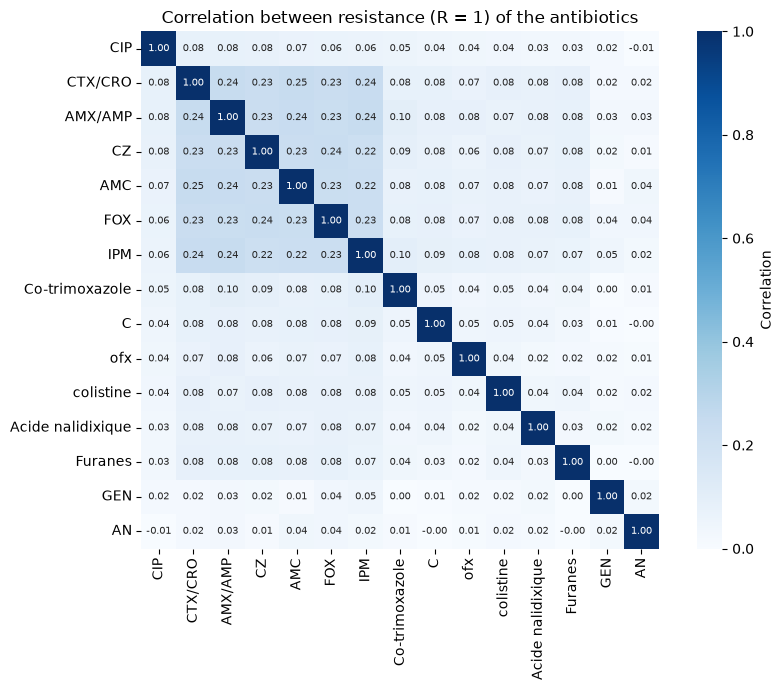

In [ ]:
resistance = bacteria_dataset[other_antibiotics].eq("R").astype(int)
resistance["CIP"] = bacteria_dataset["CIP"]
corr = resistance.corr()
order = ["CIP"] + corr["CIP"].drop("CIP").sort_values(ascending=False).index.tolist()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr.loc[order, order], annot=True, fmt=".2f", annot_kws={"size": 7}, cmap="Blues",
            vmin=0, vmax=1, square=True, cbar_kws={"label": "Correlation"}, ax=ax)
ax.set_title("Correlation between resistance (R = 1) of the antibiotics")
plt.tight_layout()
plt.show()

Correlations between antibiotics are positive, but low. The six beta-lactams form a block with higher correlation, while the other antibiotics are almost uncorrelated with each other (≤ 0.05). The correlation with CIP is at most 0.08 (beta-lactams) and about 0 for `AN`, consistent with section 7.2.

This shows there is no strong collinearity, so no antibiotic needs to be dropped for redundancy. Each antibiotic is a weak predictor on its own, so we expect modest performance and models that combine them with the species.

# **Conclusions**

The dataset introduces a compelx problem to address, with little significant relationships between the independent variables and the target. 

**Results from the EDA**

The target variable, CIP, is imbalanced, with 85.5% susceptible isolates (S) and 14.8% resistant (R). This meands that, for modeling, stratified sampling should be used for splitting the data. Also, for model performance, metrics such as accuracy will not be used, as it will misalign results.

The rest of the antibiotics are the group that contributes the most information about CIP. They should be kept for modeling using one-hot encoding, keeping the intermediate class (I) as its own category. They are not correlated with each other, so no collinearity is present in the data.

Among species, *E.coli* has the highest resistance (18.7%) and *Serratia* the lowest (4.4%). Given that *E.coli* consists of ~60% of the data, a separate binary variable for this could be created to see the effect on the model.

Clinical variables such as Age, Gender or Infection Frequency have lower priority, as they show no significant relationship with CIP.

**Modeling Plan**

1. Split the data using stratified sampling and apply encoding to the training set 
2. Build and compare the performance of different models, such as logistics regression or CART
3. Evaluate with metrics for unbalanced data: recall, F1 and PR-AUC
4. Analyse and re-evaluate options for modeling to decide on the best model

**Limitations**

The nature of the data iself introduces a limitation to modeling. The data is synthetic, so some patterns may not hold in real data and the results cannot be generalised to a clinical level.

By removing the intermediate class (I) in CIP, we are introducing a constraint, as the model will not see these values which could happen in a real setting.

Finally, the predictors signal a weak relationship with the target, so the expected performance of the model is modest. 